# E07 · Fourier C: low-frequency equaliser as the model's first layer

**One change:** the model gets a fixed first layer (`LowFreqEqualizer`, `src/fourier.py`) that brings
every image's **low-frequency energy** (large-scale contrast, frequencies up to 0.05 cycles per pixel)
to the same level per band, by at most 1.5× up or down. It is part of the model, so it acts on
training **and** Kaggle images alike. The target level is the median of the (normalised) training
images. No learnable parameters. See `05_fourier_analysis`.

Everything else is identical to `E04_contrast_aug` (EfficientNet-B0, 12 bands, `hist_split`-corrected
training images, contrast/brightness augmentation, same hyperparameters). Section 7 also applies
**AdaBN (balanced)**, so the result can be compared with the current best (68.18%).

| Reference | Kaggle public |
|---|---|
| E04 contrast aug | 64.39% |
| E04 contrast aug + AdaBN balanced | 68.18% |

**Train or load.** `LOAD_RUN` points to this experiment's saved run: the notebook loads its
weights and recomputes every result and the submission file in about a minute. Set
`LOAD_RUN = None` to train a new model (about 20 minutes on an M4 GPU).

## 1 · Setup

In [1]:
import json
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import classification_report

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import CLASSES, PROJECT_ROOT, TEST_BANDS
from src.experiment import (adabn_balanced, class_mix, find_run, kaggle_monitor,
                            load_experiment_data, plot_class_mix, plot_confusion_matrix,
                            plot_training_curves, view_agreement)
from src.fourier import low_freq_energy
from src.models import MEDIUM_TRACK_LIMIT, build_model
from src.plot_style import apply_style
from src.training import (Normalizer, TrainConfig, fit, load_run, new_run_dir, predict_proba,
                          predict_views, save_run, write_submission)
from src.utils import count_parameters, describe_device, get_device, seed_everything

apply_style()

# ---- Experiment settings ---------------------------------------------------------------
NOTEBOOK = "E07_fourier_C_layer"
RUN_NAME = "lowfreq_eq_contrast_aug_hist_split_effb0"
DESCRIPTION = "E04 + Fourier C: low-frequency equaliser as first layer"
LOAD_RUN = "runs/2026-10-12_1213_lowfreq_eq_contrast_aug_hist_split_effb0"   # None = train a new model
CORRECTIONS = ['hist_split']   # applied to EuroSAT images, in this order
MODEL = "efficientnet_b0"
BANDS = list(TEST_BANDS)              # all 12 bands
SEED = 42
cfg = TrainConfig(epochs=20, batch_size=128, lr=1e-3, weight_decay=1e-4,
                  label_smoothing=0.1, patience=5, augment=True,
                  photometric={"contrast": (0.9, 1.5), "band_contrast": (0.9, 1.15),
                               "brightness": (0.93, 1.07), "p": 0.8})
# -----------------------------------------------------------------------------------------

seed_everything(SEED)
device = get_device()              # CUDA > Apple GPU (MPS) > CPU
print("Device:", describe_device(device))

Device: Apple GPU (MPS)


## 2 · Data

EuroSAT images (train / val / internal test, split from `03_split`) are corrected with `CORRECTIONS`;
Kaggle images are used as they are. The normalisation statistics come from the training split only.

In [2]:
data = load_experiment_data(BANDS, CORRECTIONS, device)
normalizer = Normalizer.fit(data.X_tr)
print(data.summary())

# Target level of the low-frequency equaliser: median low-frequency energy of the normalised training images
X_tr_norm = (data.X_tr[::4].astype(np.float32) - np.array(normalizer.mean, np.float32)[:, None, None]) \
    / np.array(normalizer.std, np.float32)[:, None, None]
INPUT_LAYER = {"type": "low_freq_equalizer", "radius": 0.05, "max_factor": 1.5,
               "template": np.median(low_freq_energy(X_tr_norm), axis=0).round(4).tolist()}
del X_tr_norm

train 18,900  val 4,050  internal test 4,050  Kaggle test 4,232


## 3 · Model and training

After every epoch the model also predicts the unlabelled Kaggle images, to watch the domain shift
without spending submissions (mean confidence, predicted class shares).

In [3]:
if LOAD_RUN:
    model, normalizer, _ = load_run(PROJECT_ROOT / LOAD_RUN, device)
    history = pd.read_csv(PROJECT_ROOT / LOAD_RUN / "history.csv")
    print(f"Loaded weights and training history ({len(history)} epochs) from {LOAD_RUN}: no training")
else:
    model = build_model(MODEL, bands=BANDS, pretrained=True, input_layer=INPUT_LAYER).to(device)
    history, best_state = fit(model, data.tr_images, data.tr_labels, data.va_images, data.va_labels,
                              normalizer, cfg, monitor=kaggle_monitor(data, normalizer))

n_params = count_parameters(model)
assert n_params <= MEDIUM_TRACK_LIMIT, "too many parameters for the medium track"
print(f"{MODEL}: {n_params:,} parameters (medium track limit {MEDIUM_TRACK_LIMIT:,})")

Loaded weights and training history (20 epochs) from runs/2026-10-12_1213_lowfreq_eq_contrast_aug_hist_split_effb0: no training
efficientnet_b0: 4,022,950 parameters (medium track limit 10,000,000)


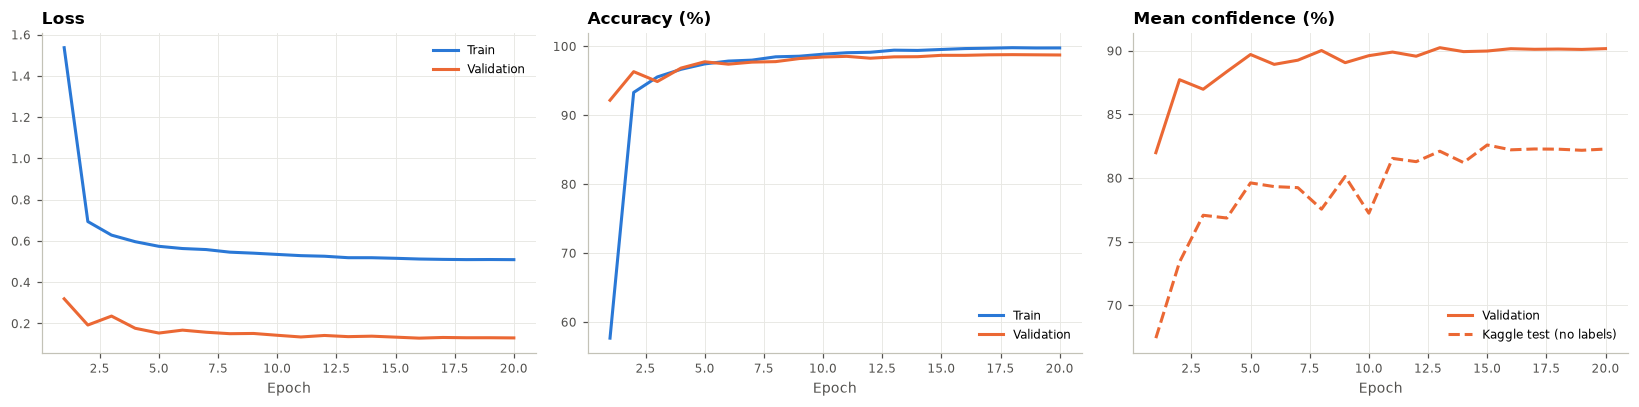

In [4]:
plot_training_curves(history)

## 4 · Internal test set

Measured once, on the best epoch: how well the model learned EuroSAT itself. It says nothing about
the Level-2A Kaggle images.

In [5]:
te_pred = predict_proba(model, data.te_images, normalizer).argmax(1)
val_acc = float(history["val_acc"].max())
test_acc = float((te_pred == data.y_te).mean())
print(f"Validation accuracy (best epoch): {val_acc:.2%}")
print(f"Internal test accuracy:           {test_acc:.2%}\n")
print(classification_report(data.y_te, te_pred, target_names=CLASSES, digits=3))

Validation accuracy (best epoch): 98.79%
Internal test accuracy:           98.77%

                      precision    recall  f1-score   support

          AnnualCrop      0.978     0.980     0.979       450
              Forest      0.996     0.996     0.996       450
HerbaceousVegetation      0.978     0.984     0.981       450
             Highway      0.984     0.987     0.985       375
          Industrial      0.995     0.992     0.993       375
             Pasture      0.990     0.967     0.978       300
       PermanentCrop      0.976     0.973     0.975       375
         Residential      0.998     0.996     0.997       450
               River      0.984     0.995     0.989       375
             SeaLake      0.998     1.000     0.999       450

            accuracy                          0.988      4050
           macro avg      0.988     0.987     0.987      4050
        weighted avg      0.988     0.988     0.988      4050



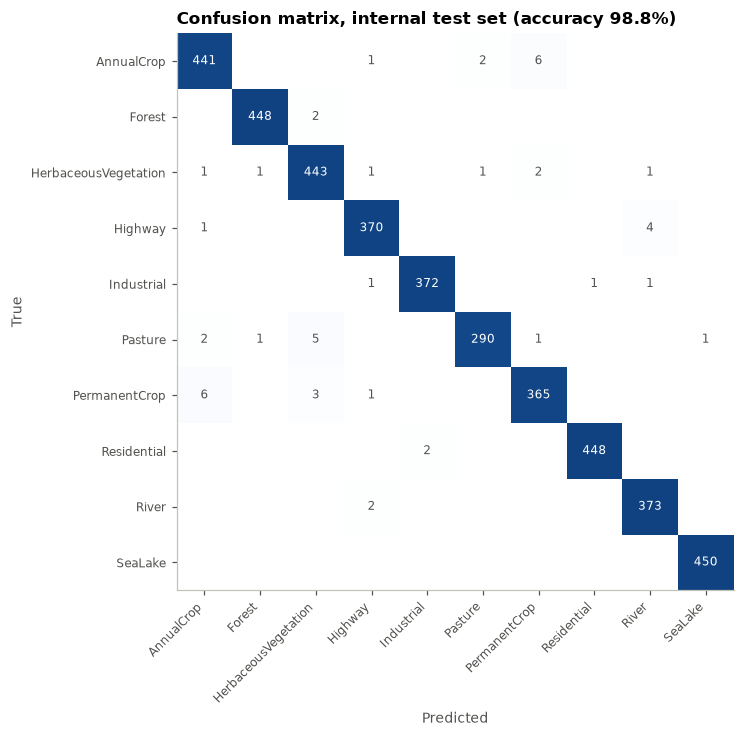

In [6]:
plot_confusion_matrix(data.y_te, te_pred, f"Confusion matrix, internal test set (accuracy {test_acc:.1%})")

## 5 · Kaggle predictions

Kaggle images as they are, normalised with the training statistics; test-time augmentation averages
the 8 rotations/flips of each image.

Mean confidence on Kaggle images: 79.3%


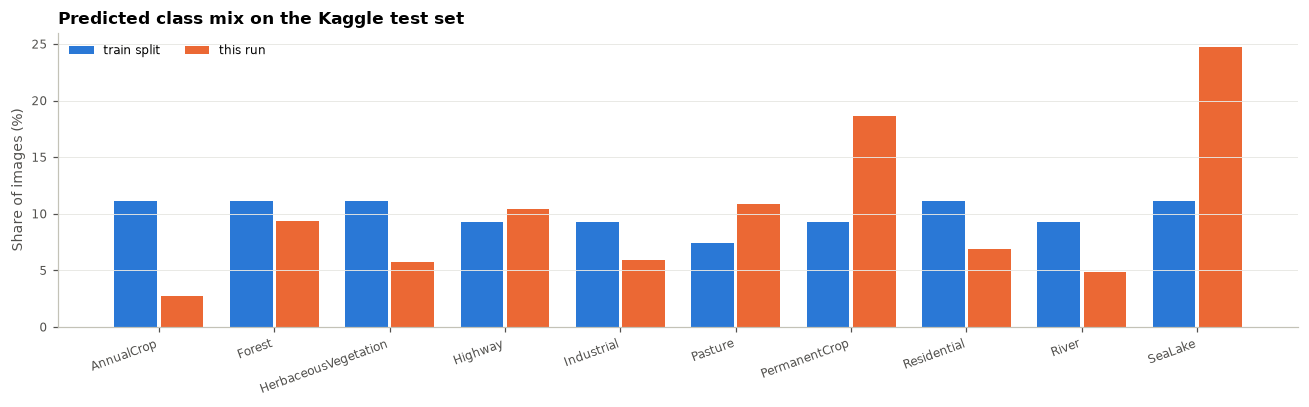

,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
train split,11.1,11.1,11.1,9.3,9.3,7.4,9.3,11.1,9.3,11.1
this run,2.7,9.4,5.7,10.4,5.9,10.8,18.6,6.9,4.8,24.7


In [7]:
kg_prob = predict_proba(model, data.kg_images, normalizer, tta=True)
kg_conf = float(kg_prob.max(1).mean())
mix = pd.DataFrame({"train split": class_mix(np.eye(10)[data.y_tr]), "this run": class_mix(kg_prob)})
print(f"Mean confidence on Kaggle images: {kg_conf:.1%}")
plot_class_mix(mix)
mix.round(1).T

## 6 · Save the run

With `LOAD_RUN` nothing is retrained or overwritten except `submission.csv`, recomputed from the saved weights.

In [8]:
if LOAD_RUN:
    run_dir = PROJECT_ROOT / LOAD_RUN
else:
    run_dir = new_run_dir(RUN_NAME)
    config = {
        "run_name": run_dir.name, "description": DESCRIPTION, "notebook": NOTEBOOK, "model": MODEL,
        "bands": BANDS, "seed": SEED, "n_params": n_params, "device": describe_device(device),
        "normalizer": asdict(normalizer), "corrections": CORRECTIONS, "train": asdict(cfg),
        "split": "split_seed42", "input_layer": INPUT_LAYER,
    }
    metrics = {
        "val_acc": val_acc, "internal_test_acc": test_acc,
        "best_epoch": int(history.loc[history["val_acc"].idxmax(), "epoch"]),
        "kaggle_mean_confidence": kg_conf,
        "kaggle_predicted_mix_pct": mix["this run"].round(2).to_dict(),
        "kaggle_public_score": None,  # fill in after submitting
    }
    save_run(run_dir, best_state, config, history, metrics)

write_submission(kg_prob, data.test_ids, run_dir / "submission.csv")
print("Run folder:", run_dir.relative_to(PROJECT_ROOT))
for f in sorted(run_dir.iterdir()):
    print(f"  {f.name:20} {f.stat().st_size / 1e6:6.2f} MB")

Run folder: runs/2026-10-12_1213_lowfreq_eq_contrast_aug_hist_split_effb0
  config.json            0.00 MB
  history.csv            0.01 MB
  metrics.json           0.00 MB
  model.pt              16.36 MB
  submission.csv         0.06 MB


## 7 · With AdaBN (balanced)

As in `E03_adabn`: re-measure the BatchNorm statistics on Kaggle images, using all land images plus
enough water images to match the training water share. Saved as a second run folder. With `LOAD_RUN`,
the saved adapted weights are loaded instead of re-measuring.

In [9]:
if LOAD_RUN:
    ada_dir = find_run(f"adabn_balanced_{RUN_NAME}")
    ada_model, ada_norm, _ = load_run(ada_dir, device)
    print("Loaded adapted weights from", ada_dir.relative_to(PROJECT_ROOT))
else:
    ada_model, ada_norm, _ = load_run(run_dir, device)
    ada_model, bn_idx = adabn_balanced(ada_model, ada_norm, data, SEED)

views_plain = predict_views(model, data.kg_images, normalizer)
views_ada = predict_views(ada_model, data.kg_images, ada_norm)
prob_ada = views_ada.mean(0)

if not LOAD_RUN:
    ada_dir = new_run_dir(f"adabn_balanced_{RUN_NAME}")
    torch.save({k: v.detach().cpu() for k, v in ada_model.state_dict().items()}, ada_dir / "model.pt")
    ada_config = {**json.loads((run_dir / "config.json").read_text()), "run_name": ada_dir.name,
                  "description": DESCRIPTION + " + AdaBN balanced", "base_run": str(run_dir.relative_to(PROJECT_ROOT)),
                  "method": "adabn_balanced", "n_bn_images": int(len(bn_idx))}
    ada_metrics = {"kaggle_mean_confidence": float(prob_ada.max(1).mean()),
                   "kaggle_view_agreement": view_agreement(views_ada),
                   "kaggle_predicted_mix_pct": class_mix(prob_ada).round(2).to_dict(),
                   "kaggle_public_score": None}
    (ada_dir / "config.json").write_text(json.dumps(ada_config, indent=2))
    (ada_dir / "metrics.json").write_text(json.dumps(ada_metrics, indent=2))
write_submission(prob_ada, data.test_ids, ada_dir / "submission.csv")

sealake = CLASSES.index("SeaLake")
pd.DataFrame({
    "confidence (%)": [views_plain.mean(0).max(1).mean() * 100, prob_ada.max(1).mean() * 100],
    "view agreement (%)": [view_agreement(views_plain) * 100, view_agreement(views_ada) * 100],
    "SeaLake (%)": [(views_plain.mean(0).argmax(1) == sealake).mean() * 100, (prob_ada.argmax(1) == sealake).mean() * 100],
}, index=["this run", "this run + AdaBN balanced"]).round(1)

Loaded adapted weights from runs/2026-10-12_1214_adabn_balanced_lowfreq_eq_contrast_aug_hist_split_effb0


,confidence (%),view agreement (%),SeaLake (%)
this run,79.300003,73.2,24.7
this run + AdaBN balanced,73.300003,72.1,24.6


## 8 · Conclusion

**Kaggle public score (with AdaBN): 67.90%**, −0.3 points vs the current best (`E04` contrast aug + AdaBN, 68.18%).

**The Fourier layer is neutral.** It removes large-scale contrast differences by design, but also some real information (uniform vs patchy areas), and AdaBN already handles most of the contrast shift.

The public leaderboard uses about half of the 4,232 test images, so differences below about 1 point
(roughly 20 images) are within noise. Summary of all three Fourier methods: `05_fourier_analysis` and the README.